## 1. Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.makedirs('images', exist_ok=True)

def format_dates(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.tick_params(axis='x', rotation=45)

In [2]:
import glob
DATA_PATH = os.path.dirname(glob.glob('/kaggle/input/**/sales.csv', recursive=True)[0]) + '/'
sales = pd.read_csv(DATA_PATH + 'sales.csv')

print(sales.shape)
sales.head()

(7432685, 7)


,Unnamed: 0,date,item_id,quantity,price_base,sum_total,store_id
0,0,2023-08-04,293375605257,1.000,47.86,47.86,1
1,1,2023-08-04,a66fdf2c0ae7,3.000,49.60,148.80,1
2,2,2023-08-04,daa46ef49b7a,0.822,379.00,311.54,1
3,3,2023-08-04,a3b49c1bf758,1.000,129.00,129.00,1
4,4,2023-08-04,ab611c5cef62,7.000,79.90,559.30,1


In [3]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7432685 entries, 0 to 7432684
Data columns (total 7 columns):
 #   Column      Dtype  
---  ------      -----  
 0   Unnamed: 0  int64  
 1   date        object 
 2   item_id     object 
 3   quantity    float64
 4   price_base  float64
 5   sum_total   float64
 6   store_id    int64  
dtypes: float64(3), int64(2), object(2)
memory usage: 396.9+ MB


In [4]:
stores = pd.read_csv(DATA_PATH + 'stores.csv')
stores

,Unnamed: 0,store_id,division,format,city,area
0,0,4,Div1,MaxiEuro,City3,1887
1,1,3,Div2,Format-7 express,City2,109
2,2,2,Div2,Format-6,City1,210
3,3,1,Div1,Format-1,City1,1500


## 2. Data Cleaning

In [5]:
sales = sales.drop(columns=['Unnamed: 0'])
stores = stores.drop(columns=['Unnamed: 0'])
sales.head()

,date,item_id,quantity,price_base,sum_total,store_id
0,2023-08-04,293375605257,1.000,47.86,47.86,1
1,2023-08-04,a66fdf2c0ae7,3.000,49.60,148.80,1
2,2023-08-04,daa46ef49b7a,0.822,379.00,311.54,1
3,2023-08-04,a3b49c1bf758,1.000,129.00,129.00,1
4,2023-08-04,ab611c5cef62,7.000,79.90,559.30,1


In [6]:
sales['date'] = pd.to_datetime(sales['date'])

print(sales['date'].dtype)
print('From:', sales['date'].min())
print('To:  ', sales['date'].max())

datetime64[ns]
From: 2022-08-28 00:00:00
To:   2024-09-26 00:00:00


In [7]:
sales.describe()

,date,quantity,price_base,sum_total,store_id
count,7432685,7.432685e+06,7.432685e+06,7.432685e+06,7.432685e+06
mean,2023-11-07 01:34:58.084933120,5.642398e+00,2.075824e+02,7.612796e+02,2.041405e+00
min,2022-08-28 00:00:00,-5.000000e+02,-2.167667e+04,-2.041080e+04,1.000000e+00
25%,2023-05-04 00:00:00,1.000000e+00,6.000000e+01,1.279000e+02,1.000000e+00
50%,2023-12-25 00:00:00,2.000000e+00,1.099000e+02,2.596000e+02,2.000000e+00
75%,2024-05-13 00:00:00,4.672000e+00,1.999000e+02,5.990000e+02,3.000000e+00
max,2024-09-26 00:00:00,4.952000e+03,2.899990e+04,6.865242e+05,4.000000e+00
std,NaN,2.740466e+01,3.372886e+02,4.789478e+03,1.206728e+00


In [8]:
pd.set_option('display.float_format', '{:.2f}'.format)
sales.describe()

,date,quantity,price_base,sum_total,store_id
count,7432685,7432685.00,7432685.00,7432685.00,7432685.00
mean,2023-11-07 01:34:58.084933120,5.64,207.58,761.28,2.04
min,2022-08-28 00:00:00,-500.00,-21676.67,-20410.80,1.00
25%,2023-05-04 00:00:00,1.00,60.00,127.90,1.00
50%,2023-12-25 00:00:00,2.00,109.90,259.60,2.00
75%,2024-05-13 00:00:00,4.67,199.90,599.00,3.00
max,2024-09-26 00:00:00,4952.00,28999.90,686524.21,4.00
std,NaN,27.40,337.29,4789.48,1.21


In [9]:
neg_qty   = (sales['quantity'] < 0).sum()
zero_qty  = (sales['quantity'] == 0).sum()
neg_price = (sales['price_base'] < 0).sum()

print('Negative quantity:', neg_qty,   f'({neg_qty / len(sales):.2%})')
print('Zero quantity:    ', zero_qty,  f'({zero_qty / len(sales):.2%})')
print('Negative price:   ', neg_price, f'({neg_price / len(sales):.2%})')

Negative quantity: 1160 (0.02%)
Zero quantity:     2438 (0.03%)
Negative price:    67 (0.00%)


In [10]:
sales[sales['quantity'] < 0].head(10)

,date,item_id,quantity,price_base,sum_total,store_id
2213,2023-08-04,eabcd9da5a8e,-1.43,4.90,-7.00,1
4956,2023-08-04,8d0a2068aa75,-4.00,126.00,-504.00,1
9957,2023-08-08,2f57275be77b,-1.00,2000.00,-2000.00,1
14012,2023-08-08,95879f411e24,-1.00,115.94,-115.94,1
16440,2023-08-09,4e0ef6cff251,-0.69,-32.39,22.19,1
30867,2023-08-17,f667cbad9c1b,-1.00,699.00,-699.00,1
32257,2023-08-17,f2db8426e5e0,-1.00,74.00,-74.00,1
43169,2023-08-20,d2a723103e16,-30.00,10.00,-300.00,1
43183,2023-08-20,6d09a07dac9a,-1.00,1490.00,-1490.00,1
45817,2023-08-20,af37779ed8b0,-1.00,89.00,-89.00,1


In [11]:
sales.sort_values('quantity', ascending=False).head(10)

,date,item_id,quantity,price_base,sum_total,store_id
7366152,2024-09-14,327c5bc1e583,4952.00,0.01,44.53,4
7404922,2024-09-21,327c5bc1e583,4874.00,0.01,43.73,4
2429889,2022-11-19,b0d24502fb66,4656.00,6.97,32462.36,1
7327303,2024-09-07,327c5bc1e583,4641.00,0.01,40.80,4
2620813,2022-12-30,b0d24502fb66,4524.00,6.92,31315.64,1
5944476,2023-12-30,b0d24502fb66,4464.00,7.91,35321.87,4
679474,2023-12-30,b0d24502fb66,4447.00,7.91,35155.01,1
7359978,2024-09-13,327c5bc1e583,4324.00,0.01,37.89,4
7398691,2024-09-20,327c5bc1e583,4298.00,0.01,38.51,4
7321171,2024-09-06,327c5bc1e583,4292.00,0.01,37.96,4


In [12]:
before = len(sales)
sales = sales[(sales['quantity'] > 0) & (sales['price_base'] > 0)]

print('Removed rows:  ', before - len(sales))
print('Remaining rows:', len(sales))

Removed rows:   9204
Remaining rows: 7423481


In [13]:
catalog = pd.read_csv(DATA_PATH + 'catalog.csv')
catalog = catalog.drop(columns=['Unnamed: 0'], errors='ignore')

suspects = ['327c5bc1e583', 'b0d24502fb66']
catalog[catalog['item_id'].isin(suspects)]

,item_id,dept_name,class_name,subclass_name,item_type,weight_volume,weight_netto,fatness
48581,b0d24502fb66,ВСПОМОГАТЕЛЬНАЯ ГРУППА,ПЛАТНЫЕ ПАКЕТЫ,ПЛАТНЫЕ ПАКЕТЫ,Упаковочный Материал,NaN,NaN,NaN


**Finding:** Item `b0d24502fb66` belongs to *Auxiliary Group → Paid Bags (Packaging Material)*.
Item `327c5bc1e583` is not in the catalog, but has a price of 0.01 and sells thousands of units per day, so it is most likely packaging as well.
Both are not real product demand, so they will be removed.

In [14]:
item = sales[sales['item_id'] == '327c5bc1e583']

print('Rows:', len(item))
print('From', item['date'].min(), 'to', item['date'].max())
print('Stores:', item['store_id'].unique())
print(f"Share of all quantity: {item['quantity'].sum() / sales['quantity'].sum():.2%}")

Rows: 100
From 2024-09-02 00:00:00 to 2024-09-26 00:00:00
Stores: [1 2 3 4]
Share of all quantity: 0.36%


In [15]:
# Get the dept name directly from the catalog (no need to type Russian)
aux_dept = catalog.loc[catalog['item_id'] == 'b0d24502fb66', 'dept_name'].iloc[0]
aux_items = catalog[catalog['dept_name'] == aux_dept]['item_id']

total_qty = sales['quantity'].sum()
aux_qty   = sales[sales['item_id'].isin(aux_items)]['quantity'].sum()
item_qty  = sales[sales['item_id'] == '327c5bc1e583']['quantity'].sum()

print('Items in auxiliary dept:', len(aux_items))
print(f'Auxiliary dept share of quantity: {aux_qty / total_qty:.2%}')
print(f'Item 327c5bc1e583 share:          {item_qty / total_qty:.2%}')

Items in auxiliary dept: 3722
Auxiliary dept share of quantity: 7.41%
Item 327c5bc1e583 share:          0.36%


In [16]:
exclude = set(aux_items) | {'327c5bc1e583'}

before = len(sales)
sales = sales[~sales['item_id'].isin(exclude)]
print('Removed rows:', before - len(sales))

Removed rows: 14915


## 3. Daily Demand per Store & EDA

In [17]:
daily = (sales
         .groupby(['store_id', 'date'])['quantity']
         .sum()
         .reset_index())

print(daily.shape)
daily.head()

(2571, 3)


,store_id,date,quantity
0,1,2022-08-28,24268.96
1,1,2022-08-29,24721.23
2,1,2022-08-30,23729.90
3,1,2022-08-31,26065.13
4,1,2022-09-01,32522.31


In [18]:
pivot = daily.pivot(index='date', columns='store_id', values='quantity')
pivot = pivot.asfreq('D')

print('Missing days per store:')
print(pivot.isna().sum())
pivot.head()

Missing days per store:
store_id
1      0
2      0
3      1
4    472
dtype: int64


store_id,1,2,3,4
date,,,,
2022-08-28,24268.96,4666.24,4312.38,NaN
2022-08-29,24721.23,6186.77,7917.00,NaN
2022-08-30,23729.90,6203.13,8201.82,NaN
2022-08-31,26065.13,6241.25,7907.83,NaN
2022-09-01,32522.31,6615.41,7375.69,NaN


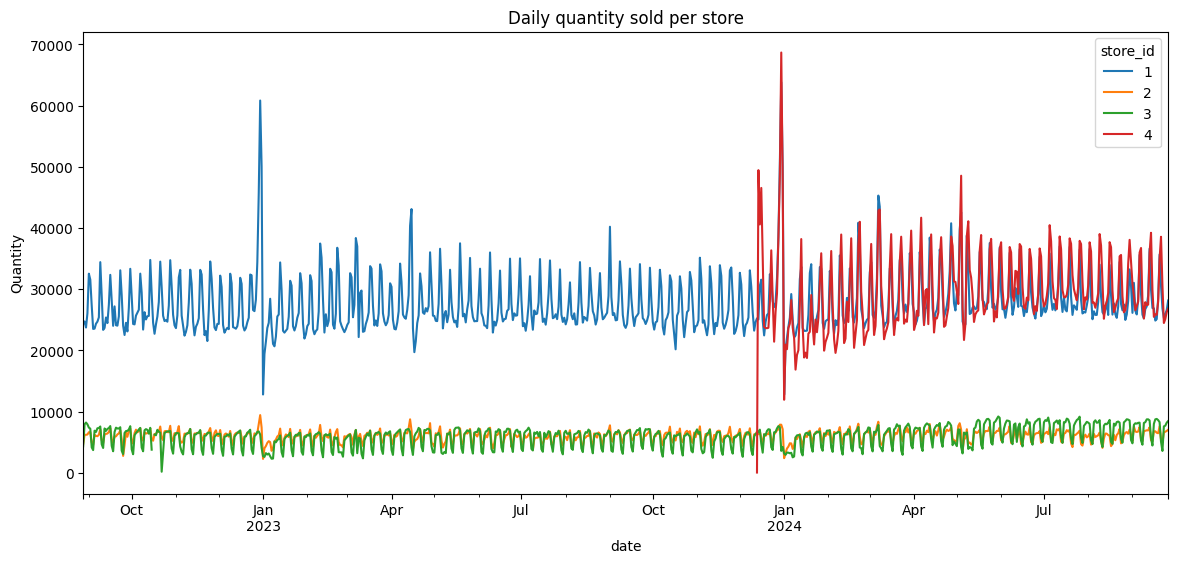

In [19]:
import matplotlib.pyplot as plt

pivot.plot(figsize=(14, 6), title='Daily quantity sold per store')
plt.ylabel('Quantity')
plt.savefig('images/daily_sales_per_store.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
print('Missing date:', pivot[pivot[3].isna()].index[0])

pivot[3] = pivot[3].interpolate()
print('Missing after fix:', pivot[3].isna().sum())

Missing date: 2022-10-16 00:00:00
Missing after fix: 0


store_id     1    2    3    4
date                         
Monday    0.89 1.00 1.07 0.82
Tuesday   0.90 1.03 1.13 0.86
Wednesday 0.93 1.05 1.16 0.87
Thursday  1.00 1.08 1.18 0.97
Friday    1.24 1.17 1.17 1.19
Saturday  1.11 0.89 0.70 1.28
Sunday    0.92 0.79 0.59 1.01


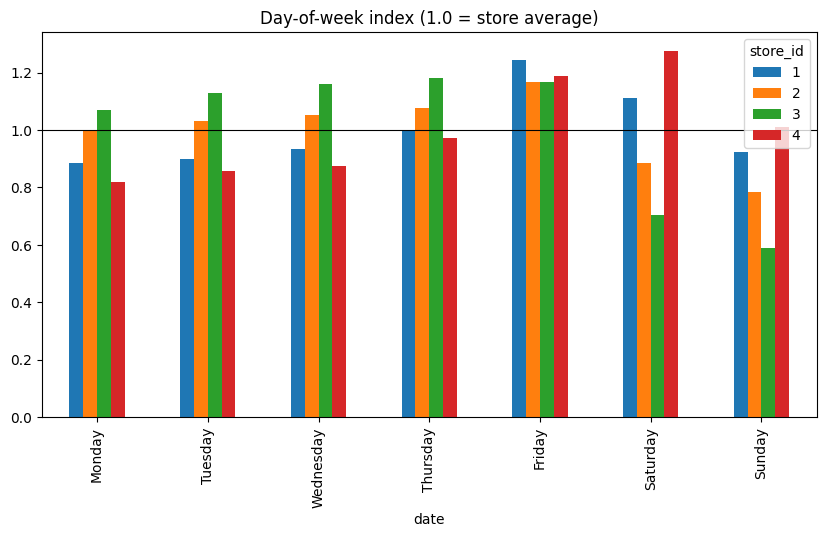

In [21]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow = pivot.groupby(pivot.index.day_name()).mean().reindex(order)
dow_index = dow / dow.mean()

print(dow_index.round(2))
dow_index.plot(kind='bar', figsize=(10, 5), title='Day-of-week index (1.0 = store average)')
plt.axhline(1, color='black', linewidth=0.8)
plt.savefig('images/day_of_week_index.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
print('Store 4 first day:', pivot[4].first_valid_index())
print()
print('Top 10 days in store 1:')
print(pivot[1].sort_values(ascending=False).head(10))

Store 4 first day: 2023-12-13 00:00:00

Top 10 days in store 1:
date
2023-12-30   63811.42
2022-12-30   60818.17
2023-12-29   50549.70
2022-12-31   50021.75
2023-12-31   49931.99
2022-12-29   45713.48
2024-03-07   45285.42
2024-03-08   43467.84
2023-04-15   43082.50
2024-05-04   42562.95
Name: 1, dtype: float64


## 4. Train / Test Split & Baselines

In [23]:
TEST_DAYS = 30
split_date = pivot.index.max() - pd.Timedelta(days=TEST_DAYS)

train = pivot[pivot.index <= split_date]
test  = pivot[pivot.index >  split_date]

print('Train:', train.index.min().date(), '->', train.index.max().date(), f'({len(train)} days)')
print('Test: ', test.index.min().date(), '->', test.index.max().date(), f'({len(test)} days)')

Train: 2022-08-28 -> 2024-08-27 (731 days)
Test:  2024-08-28 -> 2024-09-26 (30 days)


In [24]:
def wape(actual, forecast):
    return (actual - forecast).abs().sum() / actual.sum()

In [25]:
def weekday_forecast(train, test_index, weeks):
    recent = train.tail(7 * weeks)
    profile = recent.groupby(recent.index.dayofweek).mean()
    forecast = profile.loc[test_index.dayofweek]
    forecast.index = test_index
    return forecast

naive = pd.DataFrame([train.iloc[-1]] * len(test), index=test.index)

forecasts = {
    'Naive (last day)':           naive,
    'Seasonal naive (last week)': weekday_forecast(train, test.index, weeks=1),
    'Weekday avg (last 4 weeks)': weekday_forecast(train, test.index, weeks=4),
}

results = {}
for name, fc in forecasts.items():
    results[name] = wape(test, fc)

results = pd.DataFrame(results)
(results * 100).round(1)

,Naive (last day),Seasonal naive (last week),Weekday avg (last 4 weeks)
store_id,,,
1,12.10,4.80,3.70
2,9.10,6.60,10.70
3,16.20,4.50,3.70
4,13.30,4.80,5.10


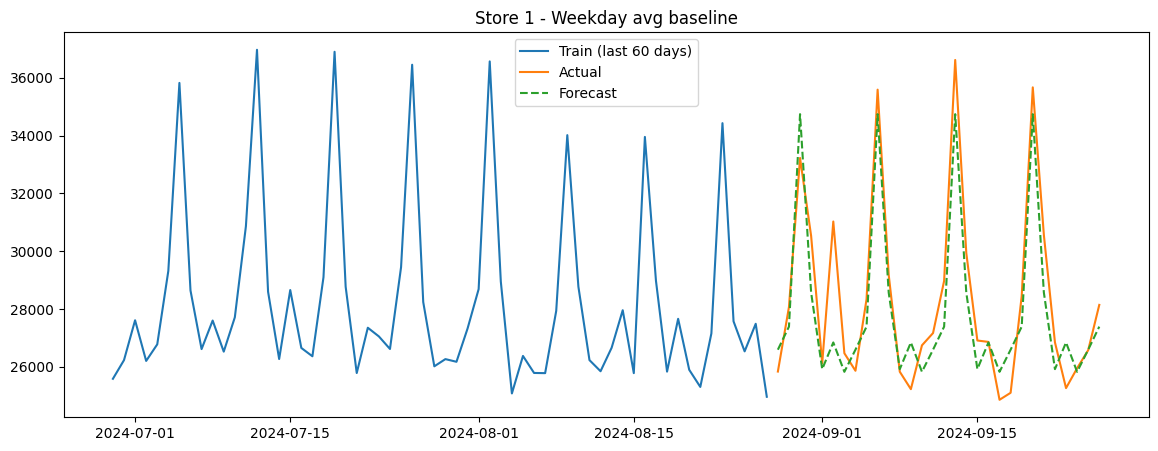

In [26]:
store = 1
best = forecasts['Weekday avg (last 4 weeks)']

plt.figure(figsize=(14, 5))
plt.plot(train[store].tail(60), label='Train (last 60 days)')
plt.plot(test[store], label='Actual')
plt.plot(best[store], label='Forecast', linestyle='--')
plt.title(f'Store {store} - Weekday avg baseline')
plt.legend()
plt.show()

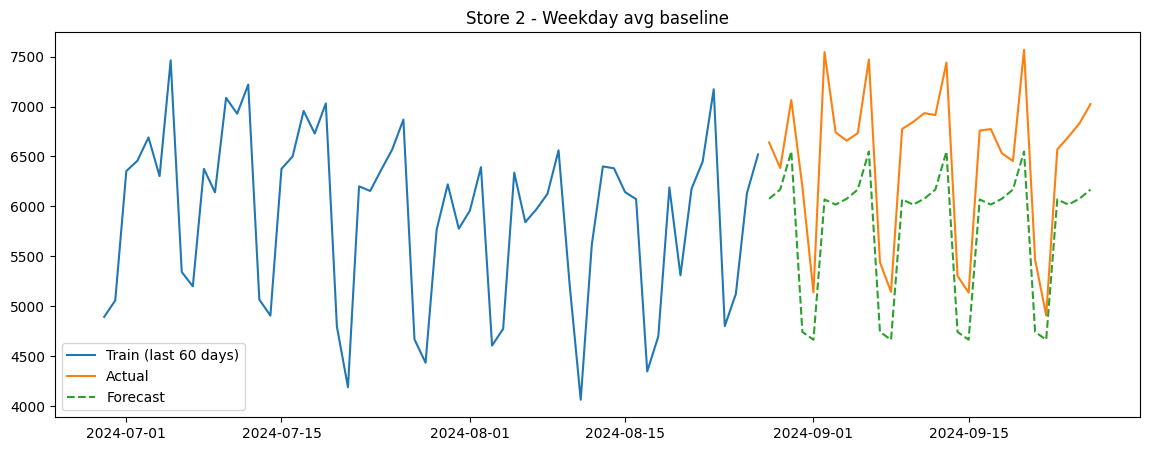

In [27]:
store = 2
best = forecasts['Weekday avg (last 4 weeks)']

plt.figure(figsize=(14, 5))
plt.plot(train[store].tail(60), label='Train (last 60 days)')
plt.plot(test[store], label='Actual')
plt.plot(best[store], label='Forecast', linestyle='--')
plt.title(f'Store {store} - Weekday avg baseline')
plt.legend()
plt.show()

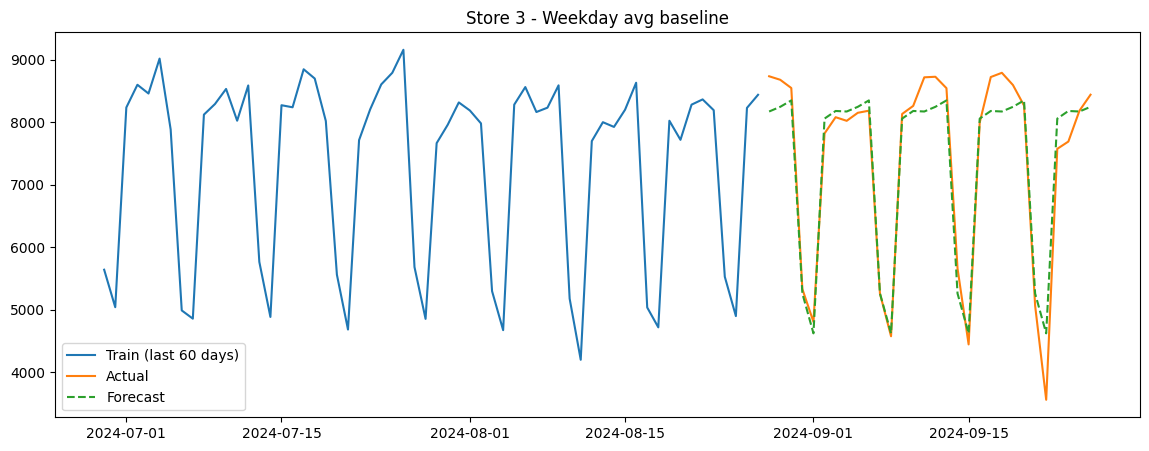

In [28]:
store = 3
best = forecasts['Weekday avg (last 4 weeks)']

plt.figure(figsize=(14, 5))
plt.plot(train[store].tail(60), label='Train (last 60 days)')
plt.plot(test[store], label='Actual')
plt.plot(best[store], label='Forecast', linestyle='--')
plt.title(f'Store {store} - Weekday avg baseline')
plt.legend()
plt.show()

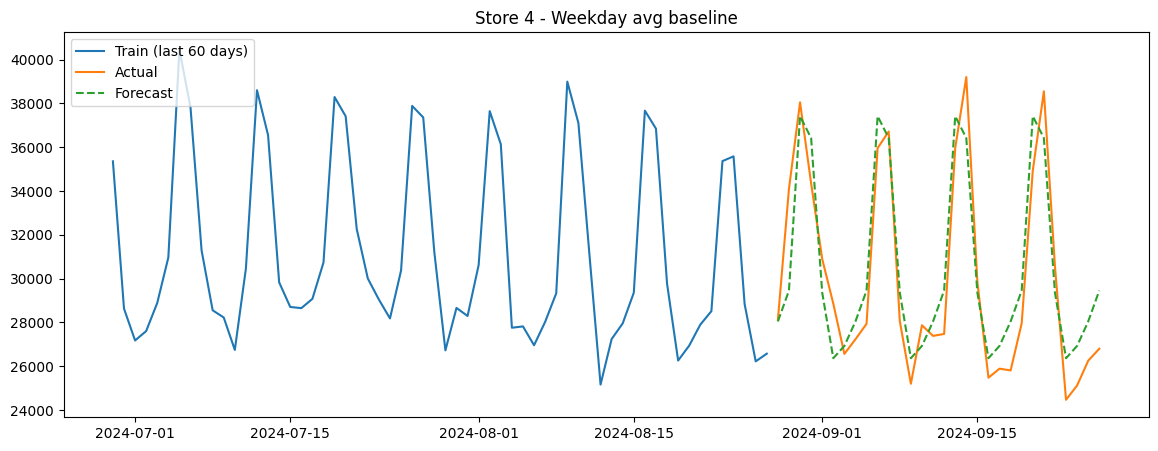

In [29]:
store = 4
best = forecasts['Weekday avg (last 4 weeks)']

plt.figure(figsize=(14, 5))
plt.plot(train[store].tail(60), label='Train (last 60 days)')
plt.plot(test[store], label='Actual')
plt.plot(best[store], label='Forecast', linestyle='--')
plt.title(f'Store {store} - Weekday avg baseline')
plt.legend()
plt.show()

## 5. Holt-Winters

In [30]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def hw_forecast(series, test_index):
    series = series.dropna().asfreq('D')
    model = ExponentialSmoothing(series,
                                 trend='add',
                                 damped_trend=True,
                                 seasonal='add',
                                 seasonal_periods=7)
    fit = model.fit()
    forecast = fit.forecast(len(test_index))
    forecast.index = test_index
    return forecast

hw = pd.DataFrame(index=test.index)
for store in train.columns:
    series = train[store]
    if store == 4:
        series = series['2024-02-01':]   # skip opening + New Year period
    hw[store] = hw_forecast(series, test.index)

forecasts['Holt-Winters'] = hw
results['Holt-Winters'] = wape(test, hw)
(results * 100).round(1)

,Naive (last day),Seasonal naive (last week),Weekday avg (last 4 weeks),Holt-Winters
store_id,,,,
1,12.10,4.80,3.70,3.70
2,9.10,6.60,10.70,6.30
3,16.20,4.50,3.70,4.90
4,13.30,4.80,5.10,5.30


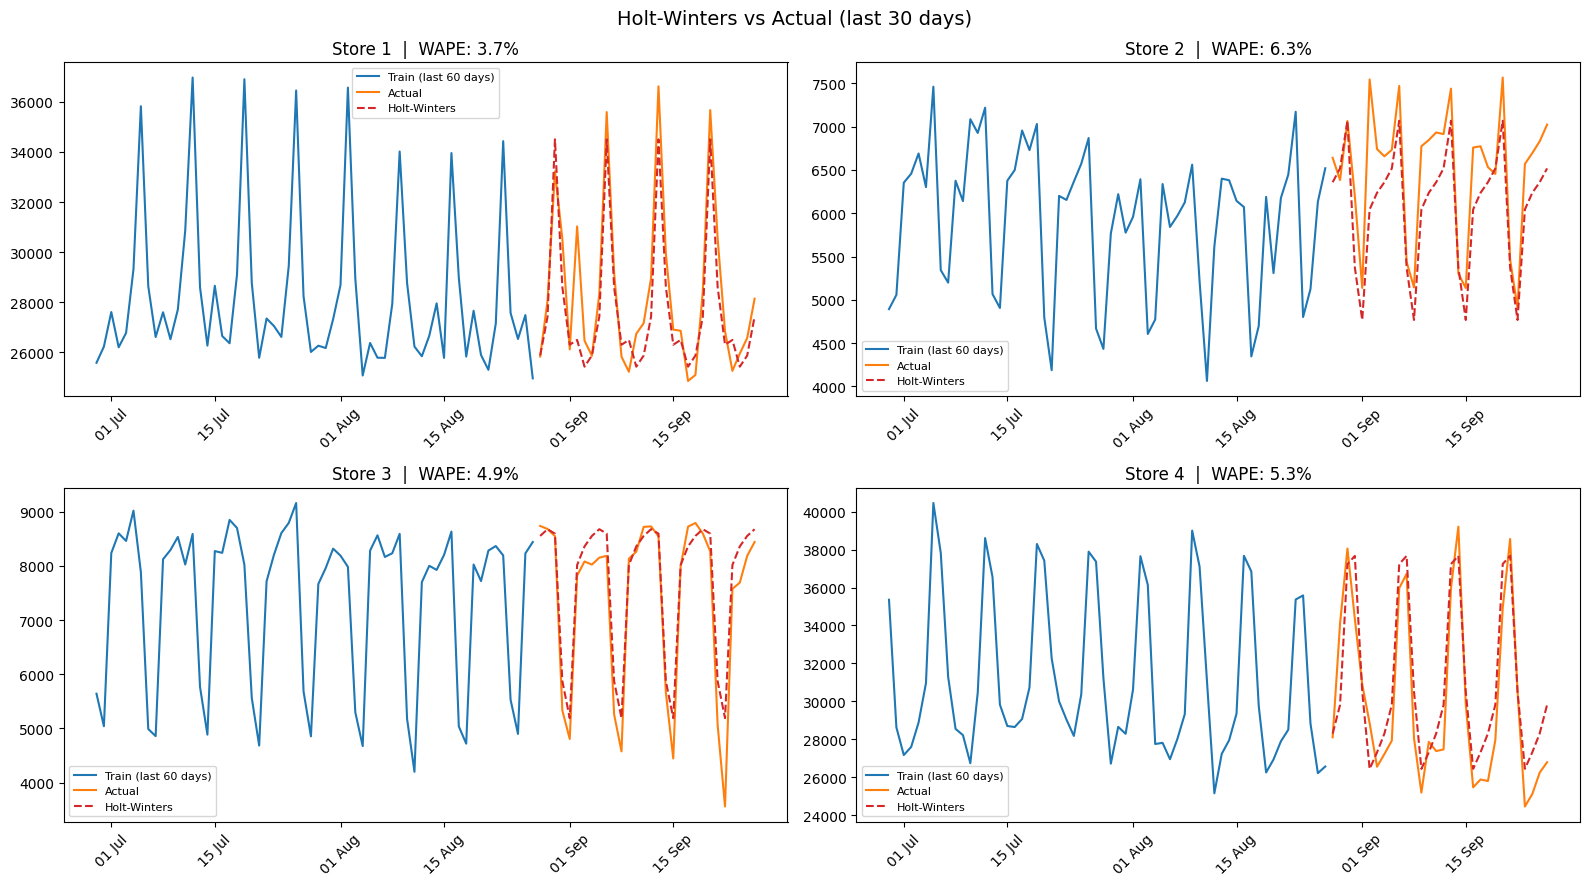

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for ax, store in zip(axes.flat, pivot.columns):
    ax.plot(train[store].tail(60), color='tab:blue', label='Train (last 60 days)')
    ax.plot(test[store], color='tab:orange', label='Actual')
    ax.plot(hw[store], color='tab:red', linestyle='--', label='Holt-Winters')

    w = wape(test[store], hw[store]) * 100
    ax.set_title(f'Store {store}  |  WAPE: {w:.1f}%')
    ax.legend(fontsize=8)
    format_dates(ax)

plt.suptitle('Holt-Winters vs Actual (last 30 days)', fontsize=14)
plt.tight_layout()
plt.savefig('images/backtest_holt_winters.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
summary = (results * 100).round(1)
summary.loc['Average'] = summary.mean().round(1)
summary.loc['Worst']   = summary.drop('Average').max()
summary

,Naive (last day),Seasonal naive (last week),Weekday avg (last 4 weeks),Holt-Winters
store_id,,,,
1,12.10,4.80,3.70,3.70
2,9.10,6.60,10.70,6.30
3,16.20,4.50,3.70,4.90
4,13.30,4.80,5.10,5.30
Average,12.70,5.20,5.80,5.00
Worst,16.20,6.60,10.70,6.30


## 6. Machine Learning (LightGBM)

In [33]:
monthly = pivot.groupby(pivot.index.to_period('M')).mean()
monthly.round(0)

store_id,1,2,3,4
date,,,,
2022-08,24696.00,5824.00,7085.00,NaN
2022-09,26744.00,5950.00,6273.00,NaN
2022-10,27093.00,6300.00,5623.00,NaN
2022-11,26548.00,6200.00,5516.00,NaN
2022-12,29321.00,6238.00,5495.00,NaN
2023-01,24804.00,5375.00,4538.00,NaN
2023-02,27089.00,5781.00,5033.00,NaN
2023-03,27773.00,5979.00,5344.00,NaN
2023-04,27898.00,6072.00,5715.00,NaN


In [34]:
df = pivot.reset_index().melt(id_vars='date', var_name='store_id', value_name='quantity')
df = df.dropna(subset=['quantity'])
df['store_id'] = df['store_id'].astype(int)
df = df.sort_values(['store_id', 'date']).reset_index(drop=True)

print(df.shape)
df.head()

(2572, 3)


,date,store_id,quantity
0,2022-08-28,1,24268.96
1,2022-08-29,1,24721.23
2,2022-08-30,1,23729.90
3,2022-08-31,1,26065.13
4,2022-09-01,1,32522.31


In [35]:
# Calendar features
df['dayofweek'] = df['date'].dt.dayofweek
df['month']     = df['date'].dt.month

# Special days we found in the EDA
peak_days = pd.to_datetime([
    '2022-12-29', '2022-12-30', '2022-12-31',   # New Year
    '2023-12-29', '2023-12-30', '2023-12-31',
    '2023-03-07', '2023-03-08',                 # Women's Day
    '2024-03-07', '2024-03-08',
    '2023-04-15', '2024-05-04',                 # Saturday before Orthodox Easter
])
df['is_peak_day'] = df['date'].isin(peak_days).astype(int)
df['is_jan_1_2']  = ((df['date'].dt.month == 1) & (df['date'].dt.day <= 2)).astype(int)

# Lag features (all older than 30 days -> no leakage)
g = df.groupby('store_id')['quantity']
df['lag_35']  = g.shift(35)    # same weekday, 5 weeks ago
df['lag_42']  = g.shift(42)    # same weekday, 6 weeks ago
df['lag_364'] = g.shift(364)   # same weekday, last year
df['rolling_28_lag30'] = g.transform(lambda s: s.shift(30).rolling(28).mean())

# Store as a category + skip store 4 opening period
df['store'] = df['store_id'].astype('category')
df = df[~((df['store_id'] == 4) & (df['date'] < '2024-02-01'))].copy()
df.tail()

,date,store_id,quantity,dayofweek,month,is_peak_day,is_jan_1_2,lag_35,lag_42,lag_364,rolling_28_lag30,store
2567,2024-09-22,4,30557.41,6,9,0,0,29770.04,31077.71,NaN,30811.00,4
2568,2024-09-23,4,24465.15,0,9,0,0,26257.35,25160.22,NaN,30747.47,4
2569,2024-09-24,4,25118.80,1,9,0,0,26940.38,27238.02,NaN,30662.37,4
2570,2024-09-25,4,26250.30,2,9,0,0,27897.37,27956.71,NaN,30644.46,4
2571,2024-09-26,4,26796.59,3,9,0,0,28511.81,29357.59,NaN,30569.84,4


In [36]:
import lightgbm as lgb

features = ['store', 'dayofweek', 'month', 'is_peak_day', 'is_jan_1_2',
            'lag_35', 'lag_42', 'lag_364', 'rolling_28_lag30']

train_df = df[df['date'] <= split_date]
test_df  = df[df['date'] >  split_date].copy()

model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05,
                          num_leaves=15, random_state=42, verbose=-1)
model.fit(train_df[features], train_df['quantity'])

test_df['forecast'] = model.predict(test_df[features])
test_df[['date', 'store_id', 'quantity', 'forecast']].head(10)

,date,store_id,quantity,forecast
731,2024-08-28,1,25838.33,26222.63
732,2024-08-29,1,28070.06,27337.13
733,2024-08-30,1,33225.58,36619.83
734,2024-08-31,1,30527.95,27775.86
735,2024-09-01,1,26121.74,26313.72
736,2024-09-02,1,31027.67,25675.97
737,2024-09-03,1,26471.20,25454.96
738,2024-09-04,1,25865.87,26406.92
739,2024-09-05,1,28339.63,26553.72
740,2024-09-06,1,35587.42,35181.49


In [37]:
ml = test_df.pivot(index='date', columns='store_id', values='forecast')

forecasts['LightGBM'] = ml
results['LightGBM'] = wape(test, ml)

summary = (results * 100).round(1)
summary.loc['Average'] = summary.mean().round(1)
summary.loc['Worst']   = summary.drop('Average').max()
summary

,Naive (last day),Seasonal naive (last week),Weekday avg (last 4 weeks),Holt-Winters,LightGBM
store_id,,,,,
1,12.10,4.80,3.70,3.70,4.80
2,9.10,6.60,10.70,6.30,8.00
3,16.20,4.50,3.70,4.90,3.80
4,13.30,4.80,5.10,5.30,4.90
Average,12.70,5.20,5.80,5.00,5.40
Worst,16.20,6.60,10.70,6.30,8.00


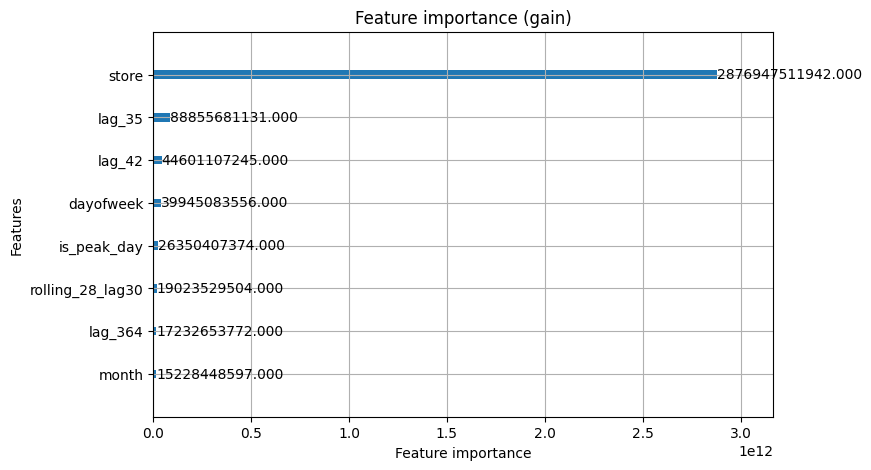

In [38]:
lgb.plot_importance(model, importance_type='gain', figsize=(8, 5),
                    title='Feature importance (gain)')
plt.show()

In [39]:
# Version 2: predict the ratio to the recent level instead of raw quantity
df['target_ratio'] = df['quantity'] / df['rolling_28_lag30']
df['lag_35_ratio'] = df['lag_35'] / df['rolling_28_lag30']
df['lag_42_ratio'] = df['lag_42'] / df['rolling_28_lag30']

features_v2 = ['store', 'dayofweek', 'month', 'is_peak_day', 'is_jan_1_2',
               'lag_35_ratio', 'lag_42_ratio']

train_v2 = df[(df['date'] <= split_date) & df['target_ratio'].notna()]
test_v2  = df[df['date'] > split_date].copy()

model_v2 = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05,
                             num_leaves=15, random_state=42, verbose=-1)
model_v2.fit(train_v2[features_v2], train_v2['target_ratio'])

# ratio x recent level = quantity
test_v2['forecast'] = model_v2.predict(test_v2[features_v2]) * test_v2['rolling_28_lag30']

ml_v2 = test_v2.pivot(index='date', columns='store_id', values='forecast')
forecasts['LightGBM v2'] = ml_v2
results['LightGBM v2'] = wape(test, ml_v2)

summary = (results * 100).round(1)
summary.loc['Average'] = summary.mean().round(1)
summary.loc['Worst']   = summary.drop('Average').max()
summary

,Naive (last day),Seasonal naive (last week),Weekday avg (last 4 weeks),Holt-Winters,LightGBM,LightGBM v2
store_id,,,,,,
1,12.10,4.80,3.70,3.70,4.80,3.50
2,9.10,6.60,10.70,6.30,8.00,7.20
3,16.20,4.50,3.70,4.90,3.80,4.70
4,13.30,4.80,5.10,5.30,4.90,8.80
Average,12.70,5.20,5.80,5.00,5.40,6.00
Worst,16.20,6.60,10.70,6.30,8.00,8.80


## 7. Final Forecast

In [40]:
future_index = pd.date_range(pivot.index.max() + pd.Timedelta(days=1), periods=30, freq='D')

final = pd.DataFrame(index=future_index)
for store in pivot.columns:
    series = pivot[store]
    if store == 4:
        series = series['2024-02-01':]
    final[store] = hw_forecast(series, future_index)

final.index.name = 'date'
print('Forecast from', future_index.min().date(), 'to', future_index.max().date())
final.round(0).head(10)

Forecast from 2024-09-27 to 2024-10-26


,1,2,3,4
date,,,,
2024-09-27,35079.00,7476.00,8192.00,36891.00
2024-09-28,29358.00,5776.00,5453.00,37541.00
2024-09-29,26502.00,5173.00,4760.00,30297.00
2024-09-30,26893.00,6470.00,7607.00,26240.00
2024-10-01,25902.00,6649.00,7955.00,26952.00
2024-10-02,26302.00,6768.00,8157.00,27797.00
2024-10-03,28187.00,6919.00,8280.00,29603.00
2024-10-04,35079.00,7476.00,8192.00,36891.00
2024-10-05,29358.00,5776.00,5453.00,37542.00


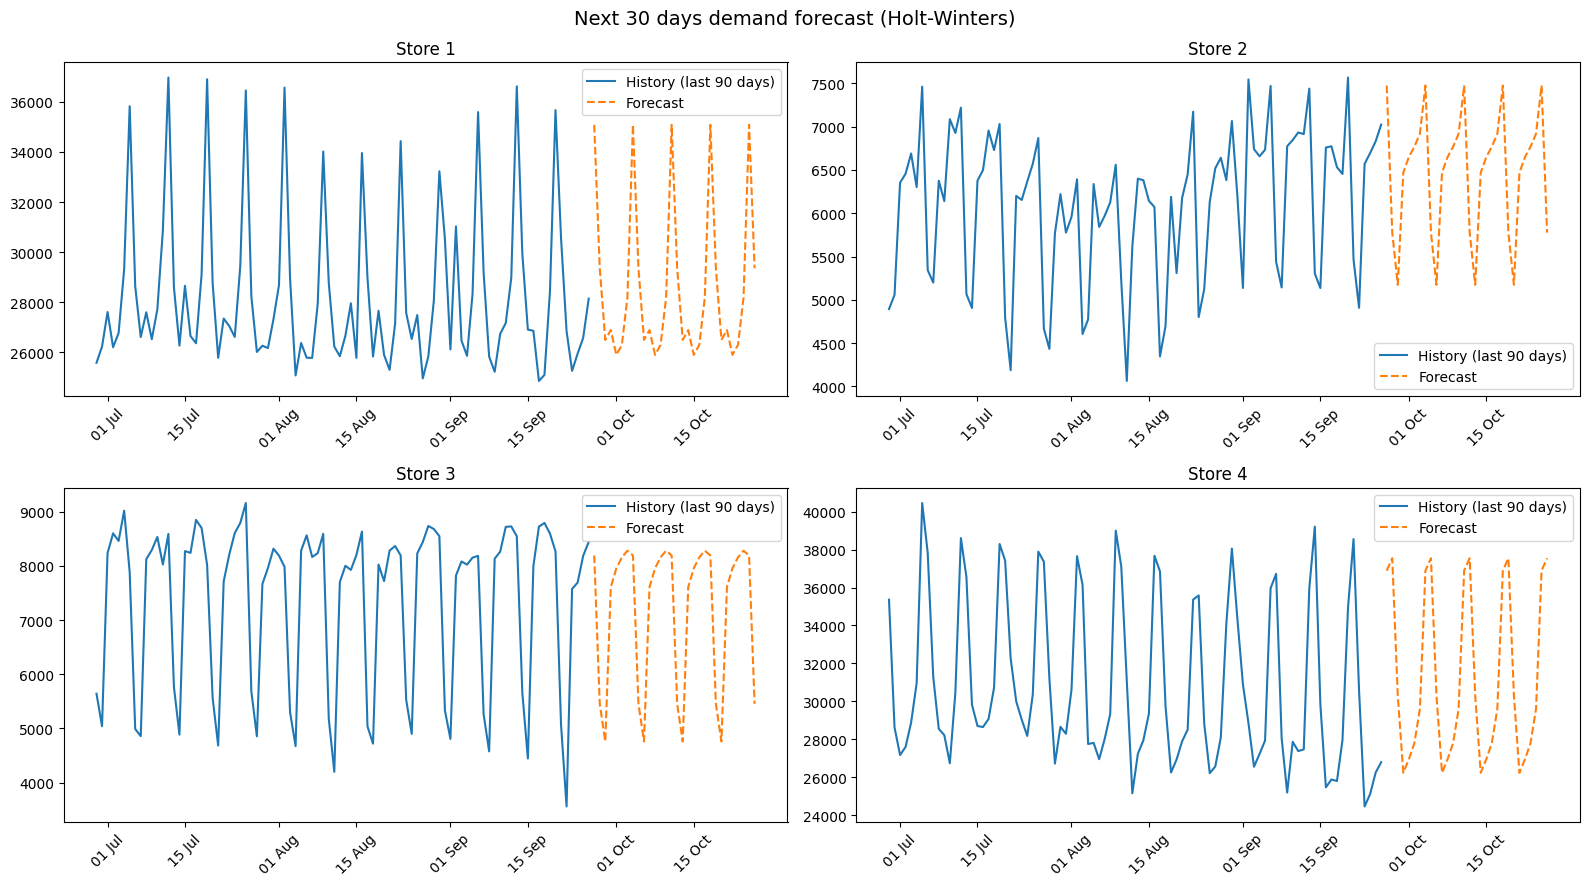

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

for ax, store in zip(axes.flat, pivot.columns):
    ax.plot(pivot[store].tail(90), label='History (last 90 days)')
    ax.plot(final[store], label='Forecast', linestyle='--')
    ax.set_title(f'Store {store}')
    ax.legend()
    format_dates(ax)

plt.suptitle('Next 30 days demand forecast (Holt-Winters)', fontsize=14)
plt.tight_layout()
plt.savefig('images/final_forecast.png', dpi=150, bbox_inches='tight')
plt.show()

In [42]:
final_summary = pd.DataFrame({
    'Forecast total (next 30 days)': final.sum(),
    'Actual total (last 30 days)':   pivot.tail(30).sum(),
    'Forecast avg per day':          final.mean(),
})
final_summary['Change %'] = (final_summary['Forecast total (next 30 days)'] /
                             final_summary['Actual total (last 30 days)'] - 1) * 100

final.round(0).add_prefix('store_').to_csv('forecast_next_30_days.csv')
summary.to_csv('model_comparison.csv')
final_summary.round(1)

,Forecast total (next 30 days),Actual total (last 30 days),Forecast avg per day,Change %
1,857329.40,851970.30,28577.60,0.60
2,194177.70,194089.40,6472.60,0.00
3,215264.50,221583.20,7175.50,-2.90
4,935741.00,901579.50,31191.40,3.80


## Conclusions

- **Data cleaning:** removed returns and data errors (< 0.05% of rows) and packaging items (paid bags), which made up ~7.8% of total quantity but are not product demand.
- **Weekly seasonality is the main driver:** accounting for it cut forecast error from 9–16% to 4–5%. Large stores peak on Friday/Saturday; small express stores peak on weekdays (store 3 is 41% below average on Sundays).
- **Final model: Holt-Winters**, with the lowest average (5.0%) and worst-case (6.3%) WAPE on the 30-day backtest.
- **ML did not win with only 4 series** (LightGBM average 5.4%), which motivated the item-level analysis in Part 2.
- **Forecast for 27 Sep – 26 Oct 2024:** total demand +1.5% vs the previous 30 days (store 4's +3.8% may be optimistic).
- **Output:** `forecast_next_30_days.csv` (daily forecast per store).